Time Series on Economist data -> Bi-Yearly(6 months) data 
-- 
for y = 'dollar_ex'

In [18]:
import pandas as pd
import numpy as np
from statsmodels.tsa.seasonal import seasonal_decompose # pip install statsmodels
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error
import os
os.chdir("C:/Users/dbda.STUDENTSDC/Desktop/Practical Machine Learning/Datasets")

In [19]:
df = pd.read_csv("ECONOMIST-BIGMAC_IND.csv")
df

,Date,local_price,dollar_ex,dollar_price,dollar_ppp,dollar_valuation,dollar_adj_valuation,euro_adj_valuation,sterling_adj_valuation,yen_adj_valuation,yuan_adj_valuation
0,31-07-2011,84.00,44.40000,1.891892,20.664207,-53.458994,-8.359064,-32.769082,-15.704950,-13.127598,-11.306250
1,31-01-2012,84.00,51.90500,1.618341,20.013247,-61.442545,-30.243509,-40.558027,-31.731846,-32.675068,-29.994497
2,31-07-2012,89.00,56.16500,1.584617,20.566147,-63.382628,-36.062061,-42.424053,-40.416215,-35.169152,-32.044926
3,31-01-2013,89.00,53.39500,1.666823,20.378277,-61.834860,-34.144084,-45.375668,-38.082988,-19.957090,-31.278135
4,31-07-2013,90.00,59.98000,1.500500,19.751280,-67.070223,-42.900426,-48.294924,-40.847889,-20.416281,-38.953357
5,31-01-2014,95.00,61.84500,1.536098,20.544242,-66.781078,-39.441019,-48.020351,-45.029990,-8.063830,-40.161290
6,31-07-2014,105.00,60.08875,1.747415,21.897810,-63.557554,-35.860400,-45.829524,-44.383094,-19.366666,-31.483226
7,31-01-2015,116.25,61.61500,1.886716,24.269311,-60.611359,-30.080400,-31.015582,-32.191003,-6.539621,-26.275242
8,31-07-2015,116.25,63.43000,1.832729,24.269311,-61.738434,-34.419669,-31.389566,-35.282042,-9.893247,-27.680525
9,31-01-2016,127.00,66.80250,1.901126,25.760649,-61.437597,-29.920296,-24.186332,-24.192781,-6.351088,-22.614793


Train Test split
-

In [30]:
y_train = df['dollar_ex'].iloc[:18]   # Gets index 0 through 17 (first 18)
y_test = df['dollar_ex'].iloc[-3:]    # Gets the last 3 observations
y_test

18    75.1975
19    73.3900
20    74.6150
Name: dollar_ex, dtype: float64

## Simple Exponential Method

In [31]:
from statsmodels.tsa.api import SimpleExpSmoothing

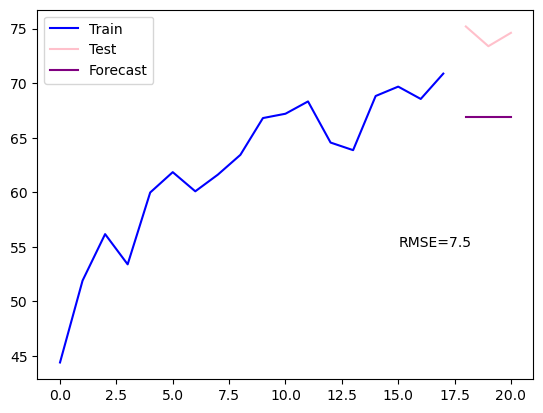

In [32]:
alpha = 0.2
ses_model = SimpleExpSmoothing(y_train).fit(smoothing_level=alpha,optimized=False)
fcast1 = ses_model.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(15, 55, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Auto tune parameters & optimized =True

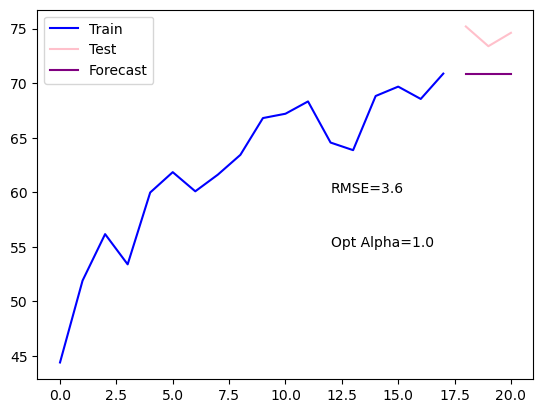

In [33]:
ses_model = SimpleExpSmoothing(y_train).fit(optimized=True)
fcast1 = ses_model.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
opt_alpha = np.round(ses_model.model.params['smoothing_level'],2)
plt.text(12,55,f"Opt Alpha={opt_alpha}")
plt.text(12,60, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Holt's Linear Trend
-

In [34]:
from statsmodels.tsa.api import Holt

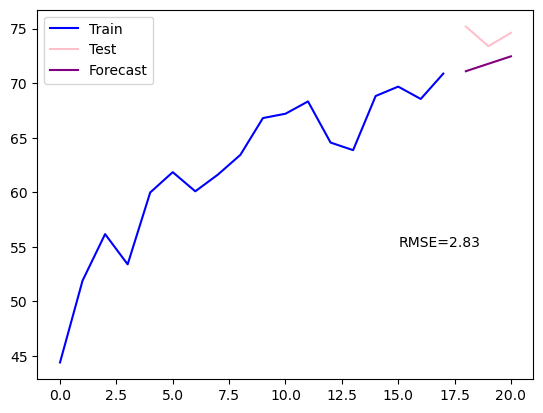

In [35]:
alpha, beta = 0.4,0.2
holt = Holt(y_train)
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta,optimized=False)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(15,55, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Auto tune parameters

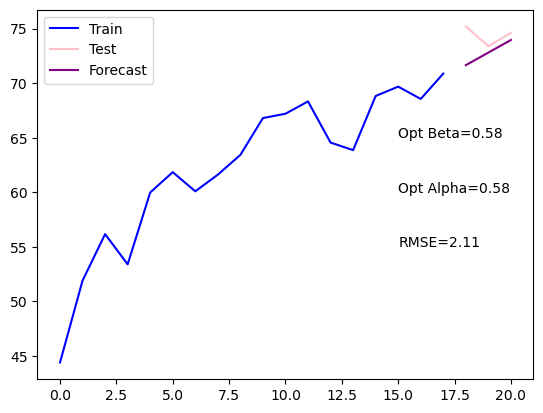

In [36]:
holt = Holt(y_train)
fit1 = holt.fit(optimized=True)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(15,55, f"RMSE={rms}")
plt.text(15,60,f"Opt Alpha={np.round(fit1.params['smoothing_level'], 2)}")
plt.text(15,65,f"Opt Beta={np.round(fit1.params['smoothing_trend'], 2)}")
plt.legend(loc='best')
plt.show()

Holt's Exponential Trend
--

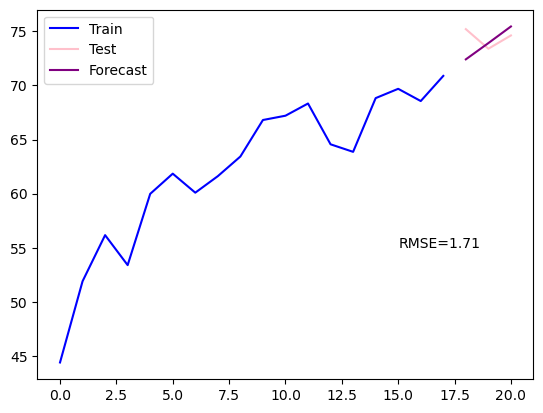

In [45]:
alpha, beta = 0.5,1.0
holt = Holt(y_train,exponential=True)
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta,optimized=False)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(15,55, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Auto tune parameters

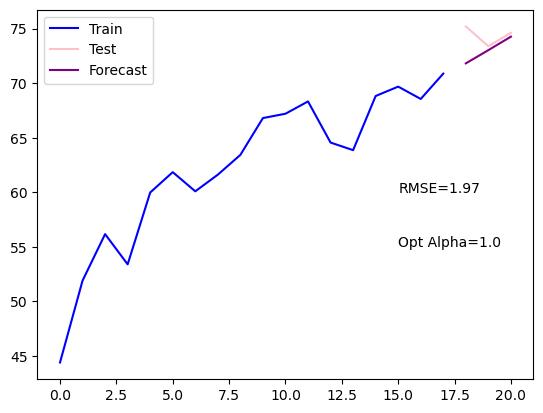

In [38]:
holt = Holt(y_train,exponential=True)
fit1 = holt.fit(optimized=True)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(15,55,f"Opt Alpha={opt_alpha}")
plt.text(15,60, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Additive Damp Trend
-

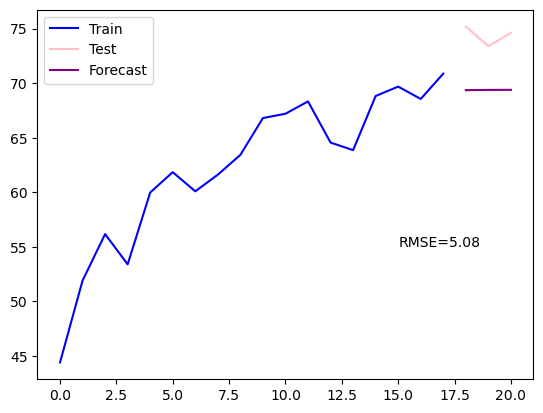

In [40]:
alpha, beta,phi = 0.4,0.2,0.3
holt = Holt(y_train,damped_trend=True)
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta,damping_trend=phi,optimized=False)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(15,55, f"RMSE={rms}")
plt.legend(loc='best')
plt.show()

Auto tune parameters

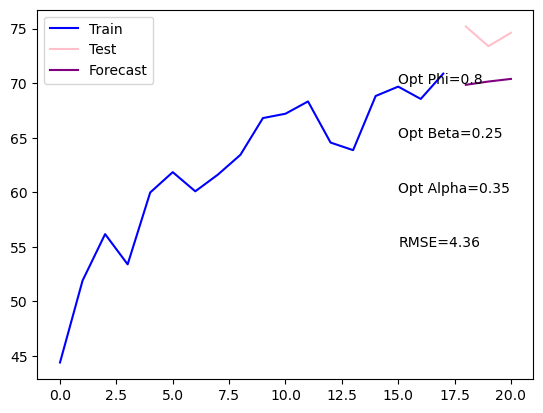

In [41]:
holt = Holt(y_train,damped_trend=True)
fit1 = holt.fit(optimized=True)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color="blue", label='Train')
y_test.plot(color="pink",label='Test')
fcast1.plot(color="purple",label='Forecast')
rms = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(15,55, f"RMSE={rms}")
plt.text(15,60,f"Opt Alpha={np.round(fit1.params['smoothing_level'], 2)}")
plt.text(15,65,f"Opt Beta={np.round(fit1.params['smoothing_trend'], 2)}")
plt.text(15,70,f"Opt Phi={np.round(fit1.params['damping_trend'], 2)}")
plt.legend(loc='best')
plt.show()